In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
from collections import deque
import matplotlib.pyplot as plt

print("Librerías cargadas correctamente. PyTorch versión:", torch.__version__)

Librerías cargadas correctamente. PyTorch versión: 2.11.0+cpu


In [10]:
class MiniMetalSlugEnv:
    def __init__(self):
        self.reset()
        
    def reset(self):
        self.jugador_x = 0
        self.obstaculo_x = 10
        return np.array([self.jugador_x, self.obstaculo_x], dtype=np.float32)
        
    def step(self, accion):
        recompensa = 0
        terminado = False
        
        if accion == 1: # Avanzar
            self.jugador_x += 1
            recompensa += 1
        elif accion == 2: # Saltar
            if abs(self.jugador_x - self.obstaculo_x) <= 2:
                recompensa += 10
            else:
                recompensa -= 1 
                
        if self.jugador_x == self.obstaculo_x and accion != 2:
            recompensa -= 50
            terminado = True
            
        if self.jugador_x >= 15:
            recompensa += 100
            terminado = True
            
        estado_siguiente = np.array([self.jugador_x, self.obstaculo_x], dtype=np.float32)
        return estado_siguiente, recompensa, terminado

In [11]:
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 24),
            nn.ReLU(),
            nn.Linear(24, 24),
            nn.ReLU(),
            nn.Linear(24, output_dim)
        )
        
    def forward(self, x):
        return self.fc(x)

env = MiniMetalSlugEnv()
input_dim = 2
output_dim = 3

model = DQN(input_dim, output_dim)
target_model = DQN(input_dim, output_dim)
target_model.load_state_dict(model.state_dict())

optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()
memory = deque(maxlen=2000)

gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
batch_size = 32

¡Entrenamiento en Notebook finalizado con éxito!


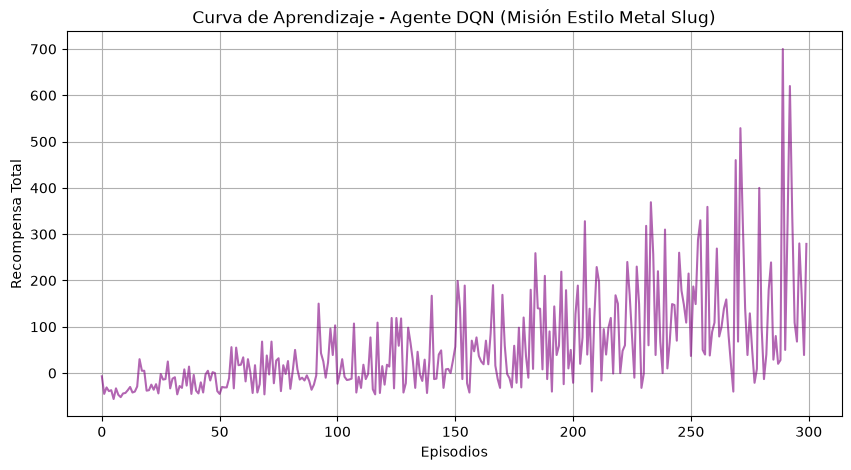

In [12]:
episodes = 300
historial_recompensas = []

for e in range(episodes):
    estado = env.reset()
    puntaje_total = 0
    
    while True:
        if random.random() < epsilon:
            accion = random.randint(0, output_dim - 1)
        else:
            with torch.no_grad():
                q_valores = model(torch.FloatTensor(estado))
                accion = torch.argmax(q_valores).item()
                
        siguiente_estado, recompensa, terminado = env.step(accion)
        memory.append((estado, accion, recompensa, siguiente_estado, terminado))
        
        estado = siguiente_estado
        puntaje_total += recompensa
        
        if len(memory) >= batch_size:
            batch = random.sample(memory, batch_size)
            estados, acciones, recompensas, siguientes_estados, terminados = zip(*batch)
            
            estados = torch.FloatTensor(np.array(estados))
            acciones = torch.LongTensor(acciones).unsqueeze(1)
            recompensas = torch.FloatTensor(recompensas)
            siguientes_estados = torch.FloatTensor(np.array(siguientes_estados))
            terminados = torch.FloatTensor(terminados)
            
            q_actuales = model(estados).gather(1, acciones).squeeze(1)
            with torch.no_grad():
                q_siguientes = target_model(siguientes_estados).max(1)[0]
                q_objetivos = recompensas + (gamma * q_siguientes * (1 - terminados))
                
            loss = criterion(q_actuales, q_objetivos)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
        if terminado:
            break
            
    if epsilon > epsilon_min:
        epsilon *= epsilon_decay
        
    historial_recompensas.append(puntaje_total)

print("¡Entrenamiento en Notebook finalizado con éxito!")

# Graficar la curva de aprendizaje
plt.figure(figsize=(10, 5))
plt.plot(historial_recompensas, color='purple', alpha=0.6)
plt.title("Curva de Aprendizaje - Agente DQN (Misión Estilo Metal Slug)")
plt.xlabel("Episodios")
plt.ylabel("Recompensa Total")
plt.grid(True)
plt.show()

In [13]:
try:
    import gym
    print("¡Gym está instalado con éxito! Versión:", gym.__version__)
except ImportError:
    try:
        import gymnasium as gym
        print("¡Gymnasium está instalado con éxito! Versión:", gym.__version__)
    except ImportError:
        print("No tienes instalado Gym ni Gymnasium en este entorno.")

No tienes instalado Gym ni Gymnasium en este entorno.


In [14]:
# Guardar los pesos del modelo DQN entrenado
torch.save(model.state_dict(), "modelo_metal_slug_dqn.pth")
print("¡Modelo guardado con éxito como 'modelo_metal_slug_dqn.pth'!")

¡Modelo guardado con éxito como 'modelo_metal_slug_dqn.pth'!


In [15]:
# Cargar el modelo ya entrenado y probarlo de forma segura
modelo_cargado = DQN(input_dim, output_dim)
modelo_cargado.load_state_dict(torch.load("modelo_metal_slug_dqn.pth"))
modelo_cargado.eval() # Modo evaluación

print("¡Modelo cargado y listo para jugar!")

estado = env.reset()
terminado = False
puntaje_prueba = 0
pasos = 0
max_pasos = 50  # Límite de seguridad para que no se quede en bucle infinito

while not terminado and pasos < max_pasos:
    with torch.no_grad():
        q_valores = modelo_cargado(torch.FloatTensor(estado))
        accion = torch.argmax(q_valores).item() # La IA elige la mejor acción
        
    estado, recompensa, terminado = env.step(accion)
    puntaje_prueba += recompensa
    pasos += 1

print(f"¡Partida de prueba terminada en {pasos} pasos! Puntaje obtenido por la IA: {puntaje_prueba}")

¡Modelo cargado y listo para jugar!
¡Partida de prueba terminada en 50 pasos! Puntaje obtenido por la IA: 428


In [18]:
!pip install pygame

  Using cached pygame-2.6.1-cp311-cp311-win_amd64.whl.metadata (13 kB)
Using cached pygame-2.6.1-cp311-cp311-win_amd64.whl (10.6 MB)



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import pygame
import torch
import torch.nn as nn
import numpy as np
import time

# 1. Definir la estructura de la Red DQN
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 24),
            nn.ReLU(),
            nn.Linear(24, 24),
            nn.ReLU(),
            nn.Linear(24, output_dim)
        )
    def forward(self, x):
        return self.fc(x)

# 2. Cargar el modelo entrenado
input_dim = 2
output_dim = 3
modelo_cargado = DQN(input_dim, output_dim)
modelo_cargado.load_state_dict(torch.load("modelo_metal_slug_dqn.pth"))
modelo_cargado.eval()

# 3. Inicializar Pygame
pygame.init()
ANCHO, ALTO = 800, 400
pantalla = pygame.display.set_mode((ANCHO, ALTO))
pygame.display.set_caption("IA Jugando - Estilo Metal Slug (DQN)")
reloj = pygame.time.Clock()

BLANCO = (255, 255, 255)
AZUL = (50, 150, 250)
ROJO = (220, 50, 50)
NEGRO = (20, 20, 20)
VERDE = (50, 200, 100)

def ejecutar_partida_visual():
    # Posiciones iniciales claras
    jugador_x = 100        # Posición fija del jugador en la pantalla para que siempre lo veas
    obstaculo_x = 400      # El obstáculo empieza más adelante para que se vea venir
    
    suelo_y = 300
    jugador_y = suelo_y
    en_aire = False
    salto_contador = 0
    
    terminado = False
    puntaje = 0
    
    # Bucle de la animación
    for _ in range(150): # Duración de la partida visual
        pantalla.fill(BLANCO)
        
        # Dibujar suelo
        pygame.draw.rect(pantalla, VERDE, (0, suelo_y + 20, ANCHO, 100))
        
        for evento in pygame.event.get():
            if evento.type == pygame.QUIT:
                pygame.quit()
                return

        if not terminado:
            # Simular estado para la IA
            estado = np.array([jugador_x, obstaculo_x], dtype=np.float32)
            with torch.no_grad():
                q_valores = modelo_cargado(torch.FloatTensor(estado))
                accion = torch.argmax(q_valores).item()
            
            # Lógica de movimiento y avance del obstáculo hacia la izquierda
            obstaculo_x -= 4  # El obstáculo se acerca
            puntaje += 1
            
            if accion == 2 and not en_aire: # Si la IA decide saltar
                en_aire = True
                
            # Física del salto
            if en_aire:
                jugador_y -= 15
                salto_contador += 1
                if salto_contador >= 10:
                    en_aire = False
                    salto_contador = 0
            else:
                if jugador_y < suelo_y:
                    jugador_y += 15

            # Colisión (si el obstáculo llega a la posición del jugador y este no saltó)
            if abs(jugador_x - obstaculo_x) < 25 and jugador_y >= suelo_y - 10:
                puntaje -= 50
                terminado = True
                
            # Si el obstáculo pasa de largo, se reinicia más adelante
            if obstaculo_x < 0:
                obstaculo_x = 800

        # Dibujar al jugador (Cuadrito Azul bien visible)
        pygame.draw.rect(pantalla, AZUL, (jugador_x, jugador_y - 30, 30, 30))
        
        # Dibujar el obstáculo (Cuadrito Rojo)
        pygame.draw.rect(pantalla, ROJO, (obstaculo_x, suelo_y - 20, 25, 40))

        # Textos en pantalla
        fuente = pygame.font.SysFont(None, 30)
        texto_puntaje = fuente.render(f"Puntaje IA: {puntaje}", True, NEGRO)
        pantalla.blit(texto_puntaje, (20, 20))
        
        if terminado:
            texto_fin = fuente.render("¡Colisión! Reiniciando...", True, ROJO)
            pantalla.blit(texto_fin, (ANCHO // 2 - 120, ALTO // 2))
            pygame.display.flip()
            time.sleep(1)
            return

        pygame.display.flip()
        reloj.tick(30) # Velocidad fluida

while True:
    ejecutar_partida_visual()

error: display Surface quit